In [2]:
pip install pandas scipy numpy


Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
from scipy.io import loadmat

data = loadmat("./SeversonBattery.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'Cycles_Flt', 'Features_mov_Flt', 'Num_Cycles_Flt', 'PCL_Flt', 'RUL_Flt', 'secondary_test_ind', 'test_ind', 'train_ind'])


In [4]:
features = data["Features_mov_Flt"]
rul = data["RUL_Flt"].flatten()
pcl = data["PCL_Flt"].flatten()
cycles = data["Cycles_Flt"].flatten()

print(features.shape)
print(rul.shape)
print(pcl.shape)
print(cycles.shape)
print(f"Features shape: {features.shape}")
print(f"RUL shape:      {rul.shape}")
print(f"PCL shape:      {pcl.shape}")
print(f"Cycles shape:   {cycles.shape}")

(99281, 8)
(99281,)
(99281,)
(99281,)
Features shape: (99281, 8)
RUL shape:      (99281,)
PCL shape:      (99281,)
Cycles shape:   (99281,)


In [5]:
inputs = np.hstack((features, cycles[:, None]))
soh = 1 - pcl
print(inputs)

[[ 1.01377922e-02  1.02366675e-02  3.18750108e+01 ... -6.68380971e+00
   3.50992778e+00  2.00000000e+00]
 [ 1.01184425e-02  1.01855037e-02  3.19032506e+01 ... -6.72043974e+00
   3.52377085e+00  3.00000000e+00]
 [ 1.00655531e-02  1.01072170e-02  3.19130349e+01 ... -6.72412358e+00
   3.50912933e+00  4.00000000e+00]
 ...
 [ 7.77588485e-03  1.40351629e-02  3.26656016e+01 ... -4.44226799e+00
   1.72779795e+00  1.79800000e+03]
 [ 7.78554352e-03  1.40635394e-02  3.27185230e+01 ... -4.42726286e+00
   1.72404377e+00  1.79900000e+03]
 [ 7.76053270e-03  1.40601889e-02  3.26668491e+01 ... -4.43801448e+00
   1.72071973e+00  1.80000000e+03]]


In [6]:
num_cycles = data["Num_Cycles_Flt"].flatten().astype(int)

print("Number of batteries:", len(num_cycles))
print("Total cycles:", num_cycles.sum())

Number of batteries: 124
Total cycles: 99281


In [7]:
batteries = []

start = 0

for i, n in enumerate(num_cycles):
    end = start + n
    
    battery = {
        "id": i + 1,
        "features": features[start:end],
        "cycle": cycles[start:end],
        "pcl": pcl[start:end],
        "rul": rul[start:end]
    }
    
    battery["soh"] = 1 - battery["pcl"]
    
    batteries.append(battery)
    start = end

print("Batteries reconstructed:", len(batteries))

Batteries reconstructed: 124


In [8]:
print("Number of batteries:", len(num_cycles))
print("Total cycle records:", num_cycles.sum())
print("Number of features:", features.shape[1])

Number of batteries: 124
Total cycle records: 99281
Number of features: 8


In [9]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [10]:
# this is the dataset 
import pandas as pd

feature_names = [
    "Slope",
    "Intercept",
    "Avg_Temperature",
    "Internal_Resistance",
    "Charge_Time",
    "dQdV_max",
    "dQdV_min",
    "dQdV_var"
]

df = pd.DataFrame(features, columns=feature_names)

df["Cycle"] = cycles
df["SoH"] = soh
df["RUL"] = data["RUL_Flt"].flatten()

df.head(10)

,Slope,Intercept,Avg_Temperature,Internal_Resistance,Charge_Time,dQdV_max,dQdV_min,dQdV_var,Cycle,SoH,RUL
0,0.010138,0.010237,31.875011,0.016742,13.341250,-0.145350,-6.683810,3.509928,2,0.973354,1850
1,0.010118,0.010186,31.903251,0.016733,13.383513,-0.116941,-6.720440,3.523771,3,0.974455,1849
2,0.010066,0.010107,31.913035,0.016716,13.397398,-0.123170,-6.724124,3.509129,4,0.975009,1848
3,0.010056,0.010079,31.924607,0.016702,13.383409,-0.126216,-6.724090,3.514826,5,0.975613,1847
4,0.010038,0.010043,31.931898,0.016687,13.374894,-0.117784,-6.746651,3.515412,6,0.975978,1846
5,0.010040,0.010035,31.926675,0.016672,13.369111,-0.120433,-6.711175,3.510442,7,0.976356,1845
6,0.010040,0.010027,31.925960,0.016659,13.377159,-0.123851,-6.702896,3.507812,8,0.976704,1844
7,0.010033,0.010015,31.918975,0.016650,13.383163,-0.125641,-6.693088,3.503736,9,0.976811,1843
8,0.010026,0.010004,31.910317,0.016641,13.387881,-0.126699,-6.682956,3.499039,10,0.976852,1842
9,0.010018,0.009988,31.900423,0.016633,13.383193,-0.127645,-6.683488,3.497239,11,0.977074,1841


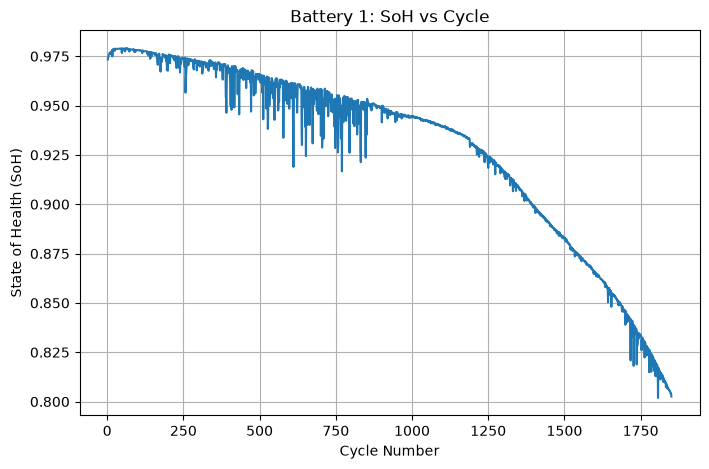

In [11]:
import matplotlib.pyplot as plt

battery = batteries[0]

plt.figure(figsize=(8, 5))
plt.plot(battery["cycle"], battery["soh"])
plt.xlabel("Cycle Number")
plt.ylabel("State of Health (SoH)")
plt.title("Battery 1: SoH vs Cycle")
plt.grid(True)
plt.show()

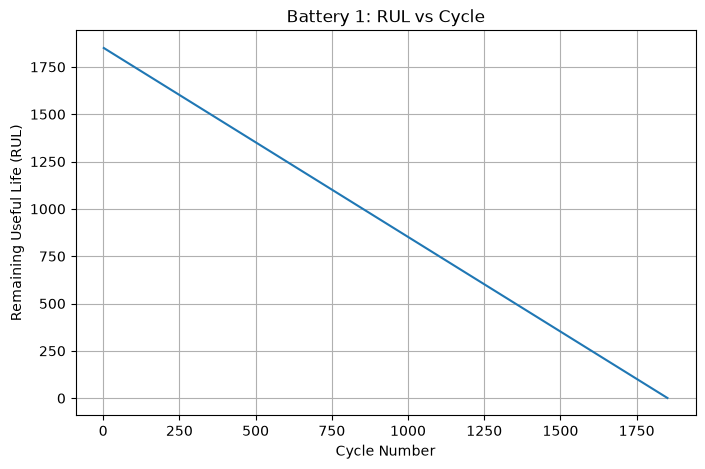

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(battery["cycle"], battery["rul"])
plt.xlabel("Cycle Number")
plt.ylabel("Remaining Useful Life (RUL)")
plt.title("Battery 1: RUL vs Cycle")
plt.grid(True)
plt.show()

In [13]:
X = np.hstack((features, cycles[:, None]))
y = soh

In [14]:
pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [15]:
print("Train indices shape:", data["train_ind"].shape)
print("Test indices shape:", data["test_ind"].shape)
print("Secondary test shape:", data["secondary_test_ind"].shape)

print("Train indices:")
print(data["train_ind"])

print("Test indices:")
print(data["test_ind"])

print("Secondary test indices:")
print(data["secondary_test_ind"])

Train indices shape: (1, 41)
Test indices shape: (1, 43)
Secondary test shape: (1, 40)
Train indices:
[[ 2  4  6  8 10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48
  50 52 54 56 58 60 62 64 66 68 70 72 74 76 78 80 82]]
Test indices:
[[ 1  3  5  7  9 11 13 15 17 19 21 23 25 27 29 31 33 35 37 39 41 43 45 47
  49 51 53 55 57 59 61 63 65 67 69 71 73 75 77 79 81 83 84]]
Secondary test indices:
[[ 85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102
  103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120
  121 122 123 124]]


In [16]:
# Get battery-level indices from the processed dataset

train_batteries = data["train_ind"].flatten() - 1
val_batteries = data["test_ind"].flatten() - 1
test_batteries = data["secondary_test_ind"].flatten() - 1

print("Training batteries:", len(train_batteries))
print("Validation batteries:", len(val_batteries))
print("Test batteries:", len(test_batteries))

Training batteries: 41
Validation batteries: 43
Test batteries: 40


In [17]:
num_cycles = data["Num_Cycles_Flt"].flatten().astype(int)

print("Number of batteries:", len(num_cycles))
print("Total cycle records:", num_cycles.sum())

Number of batteries: 124
Total cycle records: 99281


In [18]:
# Reconstruct the cycle ranges belonging to each battery

battery_ranges = []

start = 0

for n in num_cycles:
    end = start + n
    battery_ranges.append((start, end))
    start = end

print("Number of battery ranges:", len(battery_ranges))
print("First 5 ranges:", battery_ranges[:5])

Number of battery ranges: 124
First 5 ranges: [(0, np.int64(1850)), (np.int64(1850), np.int64(4008)), (np.int64(4008), np.int64(6243)), (np.int64(6243), np.int64(7675)), (np.int64(7675), np.int64(9382))]


In [19]:
# Convert battery-level indices into cycle-level data

def build_dataset(battery_indices):
    X_parts = []
    y_parts = []

    for battery_idx in battery_indices:
        start, end = battery_ranges[battery_idx]

        X_parts.append(X[start:end])
        y_parts.append(y[start:end])

    X_combined = np.vstack(X_parts)
    y_combined = np.concatenate(y_parts)

    return X_combined, y_combined


# Build the three datasets
X_train, y_train = build_dataset(train_batteries)
X_val, y_val = build_dataset(val_batteries)
X_test, y_test = build_dataset(test_batteries)


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27584, 9)
y_train: (27584,)
X_val: (30457, 9)
y_val: (30457,)
X_test: (41240, 9)
y_test: (41240,)


In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [21]:
pip install torch

Note: you may need to restart the kernel to use updated packages.


In [22]:
import torch
import torch.nn as nn


class BatteryNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(9, 64),
            nn.Tanh(),
            nn.Linear(64, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)

In [23]:
model = BatteryNN()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [24]:
import torch

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)

print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([27584, 9])
y_train: torch.Size([27584, 1])
X_val: torch.Size([30457, 9])
y_val: torch.Size([30457, 1])
X_test: torch.Size([41240, 9])
y_test: torch.Size([41240, 1])


In [25]:
model = BatteryNN()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

train_losses = []
val_losses = []

for epoch in range(100):

    model.train()

    optimizer.zero_grad()

    prediction = model(X_train_tensor)

    loss = criterion(prediction, y_train_tensor)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    model.eval()

    with torch.no_grad():
        val_prediction = model(X_val_tensor)

        val_loss = criterion(
            val_prediction,
            y_val_tensor
        )

    val_losses.append(val_loss.item())

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch}: "
            f"Train Loss = {loss.item():.6f}, "
            f"Val Loss = {val_loss.item():.6f}"
        )

Epoch 0: Train Loss = 0.621174, Val Loss = 0.576011
Epoch 10: Train Loss = 0.168994, Val Loss = 0.157410
Epoch 20: Train Loss = 0.014004, Val Loss = 0.015387
Epoch 30: Train Loss = 0.017400, Val Loss = 0.019283
Epoch 40: Train Loss = 0.006882, Val Loss = 0.008957
Epoch 50: Train Loss = 0.003975, Val Loss = 0.006014
Epoch 60: Train Loss = 0.003304, Val Loss = 0.005831
Epoch 70: Train Loss = 0.002520, Val Loss = 0.004897
Epoch 80: Train Loss = 0.002273, Val Loss = 0.004259
Epoch 90: Train Loss = 0.002028, Val Loss = 0.003966


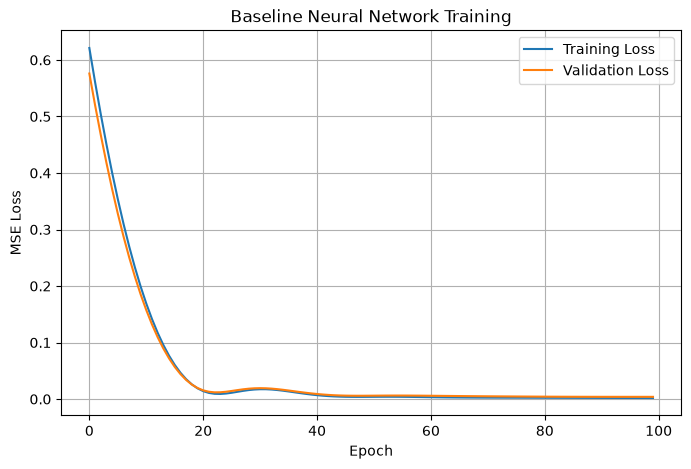

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Baseline Neural Network Training")
plt.legend()
plt.grid(True)
plt.show()

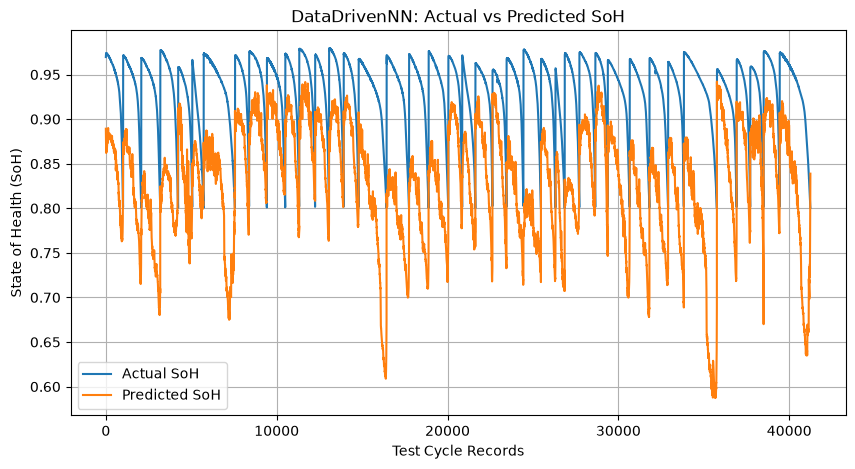

In [37]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    baseline_pred = model(X_test_tensor).numpy().flatten()

actual_soh = y_test_tensor.numpy().flatten()

plt.figure(figsize=(10, 5))

plt.plot(actual_soh, label="Actual SoH")
plt.plot(baseline_pred, label="Predicted SoH")

plt.xlabel("Test Cycle Records")
plt.ylabel("State of Health (SoH)")
plt.title("DataDrivenNN: Actual vs Predicted SoH")
plt.legend()
plt.grid(True)

plt.show()

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model.eval()

with torch.no_grad():
    baseline_pred = model(X_test_tensor).numpy().flatten()

baseline_actual = y_test_tensor.numpy().flatten()

baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline_actual,
        baseline_pred
    )
)

baseline_r2 = r2_score(
    baseline_actual,
    baseline_pred
)

print("========== BASELINE DATADRIVENNN ==========")
print(f"MAE  : {baseline_mae:.6f}")
print(f"RMSE : {baseline_rmse:.6f}")
print(f"R²   : {baseline_r2:.6f}")

========== BASELINE DATADRIVENNN ==========
MAE  : 0.106567
RMSE : 0.117365
R²   : -7.686168


In [29]:
import torch
import torch.nn as nn


class VerhulstPINN(nn.Module):

    def __init__(self, input_size=9):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.Tanh(),

            nn.Linear(64, 64),
            nn.Tanh(),

            nn.Linear(64, 32),
            nn.Tanh(),

            nn.Linear(32, 1)
        )

        # Learnable degradation rate
        self.r = nn.Parameter(
            torch.tensor(-0.01)
        )

        # Physics parameters
        self.C = 0.0
        self.K = 1.0

    def forward(self, x):
        return self.network(x)

In [30]:
def physics_loss(model, X):

    # We need gradients with respect to the input
    X_physics = X.clone().detach().requires_grad_(True)

    # Predicted SoH
    U = model(X_physics)

    # Cycle number is the 9th input
    cycle = X_physics[:, 8:9]

    # dU / dCycle
    dU_dcycle = torch.autograd.grad(
        outputs=U,
        inputs=X_physics,
        grad_outputs=torch.ones_like(U),
        create_graph=True
    )[0][:, 8:9]

    # Verhulst equation
    physics_rhs = (
        model.r
        * (U - model.C)
        * (1 - U / model.K)
    )

    # Physics residual
    residual = dU_dcycle - physics_rhs

    return torch.mean(residual ** 2)

In [31]:
def pinn_loss(model, X, y, lambda_physics=0.1):

    prediction = model(X)

    # Data loss
    data_loss = nn.functional.mse_loss(
        prediction,
        y
    )

    # Physics loss
    p_loss = physics_loss(
        model,
        X
    )

    # Total loss
    total_loss = (
        data_loss
        + lambda_physics * p_loss
    )

    return total_loss, data_loss, p_loss

In [32]:
pinn = VerhulstPINN(input_size=9)

optimizer_pinn = torch.optim.Adam(
    pinn.parameters(),
    lr=0.001
)

lambda_physics = 0.1

pinn_train_losses = []
pinn_data_losses = []
pinn_physics_losses = []
pinn_val_losses = []

for epoch in range(100):

    pinn.train()

    optimizer_pinn.zero_grad()

    total_loss, data_loss, p_loss = pinn_loss(
        pinn,
        X_train_tensor,
        y_train_tensor,
        lambda_physics
    )

    total_loss.backward()

    optimizer_pinn.step()

    pinn_train_losses.append(
        total_loss.item()
    )

    pinn_data_losses.append(
        data_loss.item()
    )

    pinn_physics_losses.append(
        p_loss.item()
    )

    # Validation
    pinn.eval()

    with torch.no_grad():

        val_prediction = pinn(
            X_val_tensor
        )

        val_loss = nn.functional.mse_loss(
            val_prediction,
            y_val_tensor
        )

    pinn_val_losses.append(
        val_loss.item()
    )

    if epoch % 10 == 0:

        print(
            f"Epoch {epoch:3d} | "
            f"Total: {total_loss.item():.6f} | "
            f"Data: {data_loss.item():.6f} | "
            f"Physics: {p_loss.item():.6f} | "
            f"Val: {val_loss.item():.6f}"
        )

Epoch   0 | Total: 0.839849 | Data: 0.839827 | Physics: 0.000224 | Val: 0.800637
Epoch  10 | Total: 0.237974 | Data: 0.237873 | Physics: 0.001007 | Val: 0.210723
Epoch  20 | Total: 0.024093 | Data: 0.023785 | Physics: 0.003087 | Val: 0.027016
Epoch  30 | Total: 0.015189 | Data: 0.014821 | Physics: 0.003673 | Val: 0.012844
Epoch  40 | Total: 0.008703 | Data: 0.008582 | Physics: 0.001211 | Val: 0.008167
Epoch  50 | Total: 0.003660 | Data: 0.003567 | Physics: 0.000922 | Val: 0.004555
Epoch  60 | Total: 0.002786 | Data: 0.002694 | Physics: 0.000918 | Val: 0.004261
Epoch  70 | Total: 0.002373 | Data: 0.002268 | Physics: 0.001055 | Val: 0.004116
Epoch  80 | Total: 0.002008 | Data: 0.001913 | Physics: 0.000950 | Val: 0.003545
Epoch  90 | Total: 0.001817 | Data: 0.001740 | Physics: 0.000774 | Val: 0.003255


In [33]:
pinn.eval()

with torch.no_grad():

    pinn_pred = pinn(
        X_test_tensor
    ).numpy().flatten()

pinn_actual = y_test_tensor.numpy().flatten()


pinn_mae = mean_absolute_error(
    pinn_actual,
    pinn_pred
)

pinn_rmse = np.sqrt(
    mean_squared_error(
        pinn_actual,
        pinn_pred
    )
)

pinn_r2 = r2_score(
    pinn_actual,
    pinn_pred
)


print("========== VERHULST PINN ==========")
print(f"MAE  : {pinn_mae:.6f}")
print(f"RMSE : {pinn_rmse:.6f}")
print(f"R²   : {pinn_r2:.6f}")


========== VERHULST PINN ==========
MAE  : 0.081624
RMSE : 0.091216
R²   : -4.246804


In [34]:
rmse_improvement = (
    (baseline_rmse - pinn_rmse)
    / baseline_rmse
) * 100

mae_improvement = (
    (baseline_mae - pinn_mae)
    / baseline_mae
) * 100

print("========== COMPARISON ==========")

print(f"Baseline RMSE : {baseline_rmse:.6f}")
print(f"PINN RMSE     : {pinn_rmse:.6f}")

print(f"\nRMSE improvement: {rmse_improvement:.2f}%")

print(f"\nBaseline MAE : {baseline_mae:.6f}")
print(f"PINN MAE     : {pinn_mae:.6f}")

print(f"\nMAE improvement: {mae_improvement:.2f}%")

========== COMPARISON ==========
Baseline RMSE : 0.117365
PINN RMSE     : 0.091216

RMSE improvement: 22.28%

Baseline MAE : 0.106567
PINN MAE     : 0.081624

MAE improvement: 23.41%


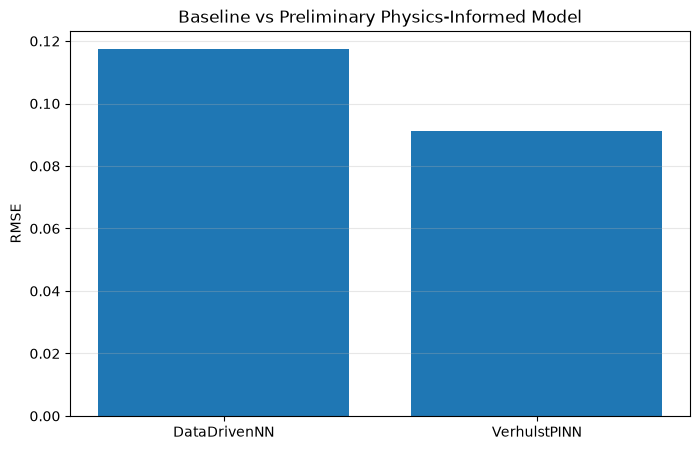

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    ["DataDrivenNN", "VerhulstPINN"],
    [baseline_rmse, pinn_rmse]
)

plt.ylabel("RMSE")
plt.title("Baseline vs Preliminary Physics-Informed Model")
plt.grid(axis="y", alpha=0.3)

plt.show()

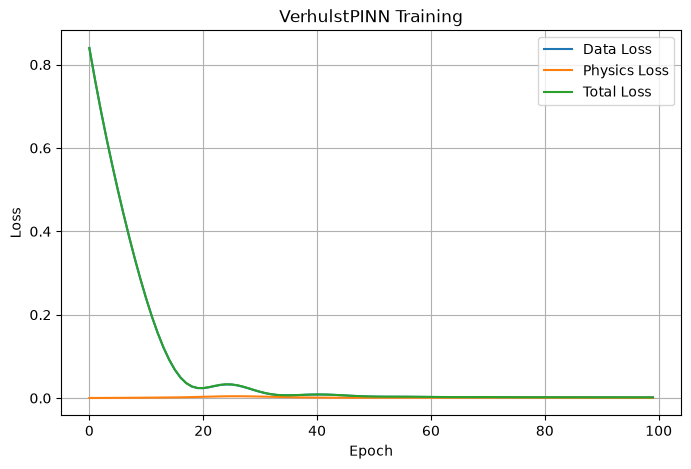

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    pinn_data_losses,
    label="Data Loss"
)

plt.plot(
    pinn_physics_losses,
    label="Physics Loss"
)

plt.plot(
    pinn_train_losses,
    label="Total Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VerhulstPINN Training")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
z